# Inflation Rate Projection

## Table of Content
#### 1. Introduction
#### 2. Objective
#### 3. Approach
#### 4. Environment setup
#### 5. EDA
#### 6. Processing
#### 7. Modelling
#### 8. Evaluation
#### 9. Conclusion

## Introduction

Accurate projections of macroeconomic indicators will enable planners and advisors to make informed decisions, allowing the government to anticipate economic shifts, implement timely interventions, and enhance national economic stability.

## Objective

Develop an AI-driven machine learning (ML) model trained on a wide range of historical and real-time economic data to enhance the accuracy and timeliness of macroeconomic forecasts, thereby providing a more robust analytical foundation for the Treasury’s work.

## Approach

In economics, statistical time-series models provide strong baselines because they are specifically designed to model temporal dependencies using limited historical observations. Given the current dataset — monthly frequency, approximately 260 observations, a single variable, and no external drivers — it is preferable to start with statistical forecasting models rather than more complex machine learning models such as XGBoost. With limited data, complex ML models may capture historical patterns very well but fail to generalize to unseen periods.

## Environment setup

#### Imports

In [147]:
# data manipulation
import pandas as pd
import numpy as np

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# statistical
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

# seasonality tests
import statsmodels.api as sm
import statsmodels.formula.api as smf

# stationarity test
from statsmodels.tsa.stattools import adfuller

# Autocorrelation function
from statsmodels.graphics.tsaplots import plot_acf

# Partial autocorrelation function
from statsmodels.graphics.tsaplots import plot_pacf

# ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# data
data = pd.read_csv("Data/Inflation_Rates.csv")

## EDA

In [148]:
# overview
print('#'*30 + ' OVERVIEW ' +'#'*30)
display(data.head())

# Shape
print('\n'+ '#'*30 + ' SHAPE ' +'#'*30)
display(data.shape)

# Nulls
print('\n'+ '#'*30 + ' NULLS ' +'#'*30)
display(data.isna().sum())

# dtypes
print('\n'+ '#'*30 + ' DATA TYPES ' +'#'*30)
display(data.dtypes)

# Duplicates
print('\n'+ '#'*30 + ' DUPLICATES ' +'#'*30)
display(data.duplicated().sum())

# Description
print('\n'+ '#'*30 + ' DESCRIBE ' +'#'*30)
num_cols = data.drop(columns = ['Year', 'Month'])
num_cols.describe()

############################## OVERVIEW ##############################


,Year,Month,Annual Average Inflation,12-Month Inflation
0,2011,November,12.82,19.72
1,2008,November,15.25,19.54
2,2011,December,14.02,18.93
3,2011,October,11.49,18.91
4,2008,October,14.13,18.74



############################## SHAPE ##############################


(262, 4)


############################## NULLS ##############################


...

Year                          int64
Month                        object
Annual Average Inflation    float64
12-Month Inflation          float64
dtype: object


############################## DUPLICATES ##############################


np.int64(1)


############################## DESCRIBE ##############################


,Annual Average Inflation,12-Month Inflation
count,262.000000,262.000000
mean,7.366069,7.218702
std,3.298838,3.846166
min,3.550000,1.850000
25%,5.190000,4.600000
50%,6.335000,6.265000
75%,8.187500,7.907500
max,17.070000,19.720000


### Convert to Time Series

In [149]:
# Create datetime column
data["Date"] = pd.to_datetime(data["Year"].astype(str) + "-" + data["Month"], format="%Y-%B")

# drop year and month
# data = data.drop(columns = ["Year", "Month"])

# Sort chronologically
data = data.sort_values("Date")

# Set Date as index
data.set_index("Date", inplace=True)

# preview
data.head(12)

,Year,Month,Annual Average Inflation,12-Month Inflation
Date,,,,
2005-01-01,2005,January,12.27,14.87
2005-02-01,2005,February,12.60,13.94
2005-03-01,2005,March,13.07,14.15
2005-04-01,2005,April,13.76,16.02
2005-05-01,2005,May,14.61,14.78
2005-06-01,2005,June,15.10,11.92
2005-07-01,2005,July,15.34,11.76
2005-08-01,2005,August,14.53,6.87
2005-09-01,2005,September,13.24,4.27


### Seasonal decomposition

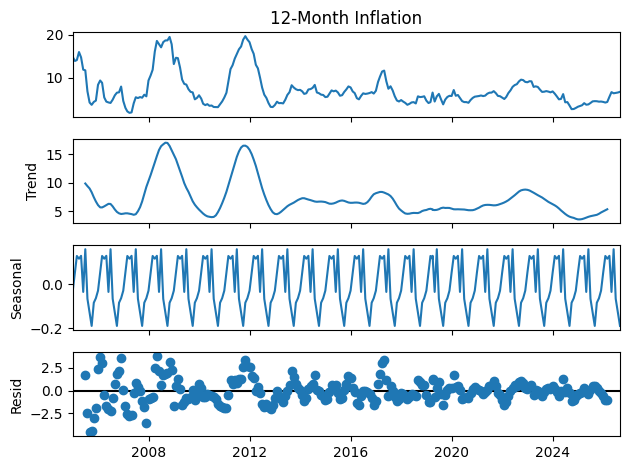

In [150]:
result = seasonal_decompose(
    data["12-Month Inflation"],
    model="additive",
    period=12
)

result.plot();

• The seasonal component only fluctuates between -0.2 and +0.15 percentage points.

• The overall inflation rate jumps by as much as 15 to 20 percentage points due to the trend, and even random noise (residuals) swings by 2.5 percentage points or more.


### Seasonality Test

H0: No significant seasonal effect exists.

H1: Seasonality exists.

**Decision rule:**

- p-value > 0.05 then Seasonality is negligible else Seasonality is significant

In [151]:
# MONTH-OF-YEAR ANOVA SEASONALITY TEST

# Create month number from datetime index
data["Month_Number"] = data.index.month

# Run ANOVA model
seasonal_model = smf.ols(
    "Q('12-Month Inflation') ~ C(Month_Number)",
    data=data
).fit()


# Generate ANOVA table
anova_results = sm.stats.anova_lm(seasonal_model)

# Display results
anova_results

,df,sum_sq,mean_sq,F,PR(>F)
C(Month_Number),11.0,11.859862,1.078169,0.070027,0.999986
Residual,250.0,3849.110296,15.396441,NaN,NaN


The ANOVA test produces a p-value of **0.999986**, which is greater than the significance level of 0.05. Therefore, we fail to reject the null hypothesis.

This supports the use of a **non-seasonal ARIMA model rather than SARIMA**.

### Stationarity Test

Does the 12-Month Inflation series have a stable statistical behaviour over time, or does it contain a changing trend that needs to be removed before modelling?

H0: Series is non-stationary

H1: Series is stationary

**Decision rule:**

- p-value > 0.05 then series is non-stationary(Fail to reject H0) else Series is stationary

In [152]:
# Run Augmented Dickey-Fuller(ADF) test
adf_result = adfuller(data["12-Month Inflation"])

# Extract results
adf_statistic = adf_result[0]
p_value = adf_result[1]

print("ADF Statistic:", adf_statistic)
print("p-value:", p_value)

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -3.550645623656336
p-value: 0.006777780702178463

Critical Values:
1%: -3.4573260719088132
5%: -2.873410402808354
10%: -2.573095980841316


- The Augmented Dickey-Fuller test produced a p-value of 0.0068. Since the p-value is below 0.05, the null hypothesis of non-stationarity is rejected.

- Therefore, the 12-Month Inflation series is considered stationary, and no differencing is required before applying ARIMA (d=0).

### Model Identification

Since the ADF test confirmed that the 12-Month Inflation series is stationary (\(d=0\)), the next step is to determine suitable values for the autoregressive (\(p\)) and moving average (\(q\)) orders of the ARIMA model.

- **ACF (Autocorrelation Function)** helps identify the Moving Average (MA) order, \(q\).
- **PACF (Partial Autocorrelation Function)** helps identify the Autoregressive (AR) order, \(p\).

<Figure size 1000x500 with 0 Axes>

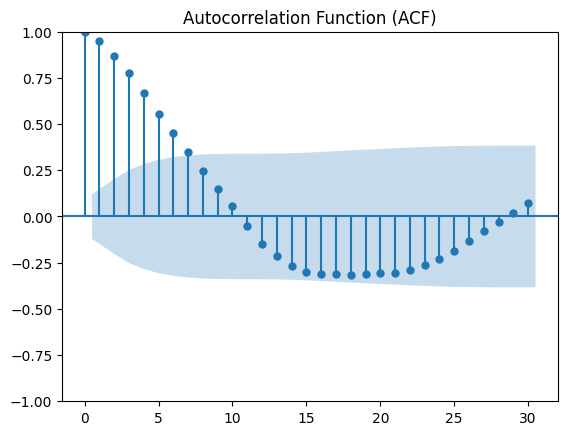

In [153]:
# Auto correlation function
plt.figure(figsize=(10,5))

plot_acf(
    data["12-Month Inflation"],
    lags=30
)

plt.title("Autocorrelation Function (ACF)")
plt.show()

<Figure size 1000x500 with 0 Axes>

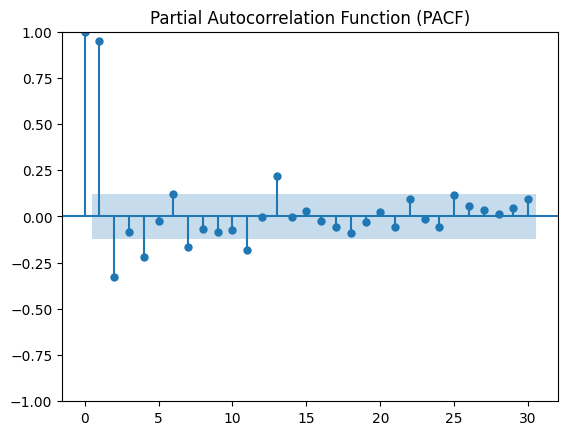

In [154]:
# Partial Autocorrelation Function
plt.figure(figsize=(10,5))

plot_pacf(
    data["12-Month Inflation"],
    lags=30,
    method="ywm"
)

plt.title("Partial Autocorrelation Function (PACF)")
plt.show()

### Model Selection

In [155]:
# model selection
models = {
    "ARIMA(1,0,0)": (1,0,0),
    "ARIMA(1,0,1)": (1,0,1),
    "ARIMA(2,0,0)": (2,0,0),
    "ARIMA(2,0,1)": (2,0,1),
    "ARIMA(2,0,2)": (2,0,2),
    "ARIMA(3,0,0)": (3,0,0),   
}

results = {}

for name, order in models.items():
    model = ARIMA(
        data["12-Month Inflation"],
        order=order
    )
    
    fitted_model = model.fit()
    
    results[name] = {
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic
    }

pd.DataFrame(results).T.sort_values("AIC")

C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency inform

,AIC,BIC
"ARIMA(2,0,2)",755.790904,777.200971
"ARIMA(2,0,1)",763.083231,780.924953
"ARIMA(2,0,0)",765.165166,779.438544
"ARIMA(3,0,0)",766.658638,784.500361
"ARIMA(1,0,1)",770.253922,784.527300
"ARIMA(1,0,0)",808.055114,818.760147


### ARIMA Model Selection

* Several candidate ARIMA models were evaluated using Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC).

* The ARIMA(2,0,2) model achieved the lowest AIC (755.79) and BIC (777.20), indicating the best trade-off between model fit and model complexity.

* Therefore, ARIMA(2,0,2) was selected as the preferred forecasting model for the 12-Month Inflation series.

### Residual Diagnostics

- Did ARIMA(2,0,0) actually capture all the important patterns in inflation?

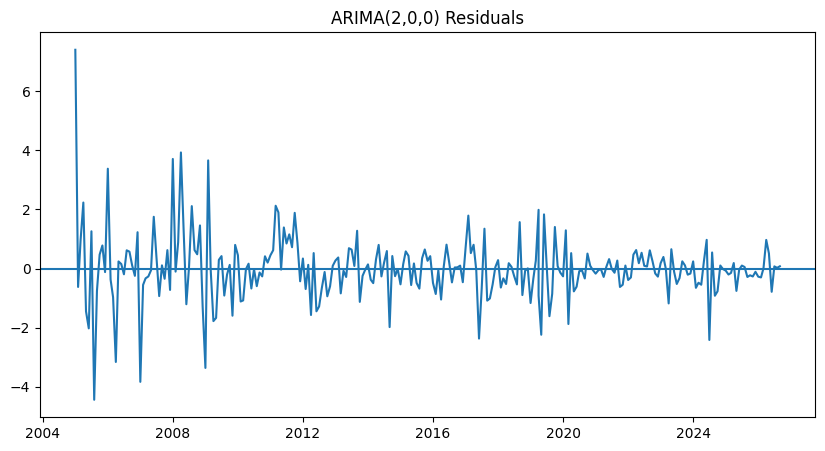

In [156]:
# Residual plot (visual check)
residuals = fitted_model.resid

plt.figure(figsize=(10,5))
plt.plot(residuals)
plt.axhline(y=0)
plt.title("ARIMA(2,0,0) Residuals")
plt.show()

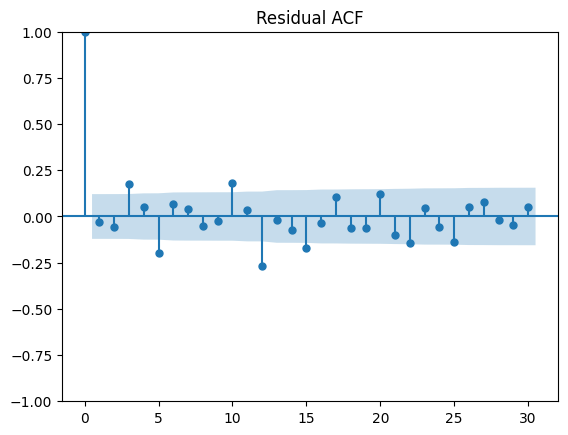

In [157]:
# Residual ACF (autocorrelation check)
plot_acf(residuals, lags=30)
plt.title("Residual ACF")
plt.show()

In [158]:
from statsmodels.stats.diagnostic import acorr_ljungbox

acorr_ljungbox(
    fitted_model.resid,
    lags=[5,10,15,20],
    return_df=True
)

,lb_stat,lb_pvalue
5,20.643345,9.458457e-04
10,32.023084,3.969062e-04
15,61.665846,1.301349e-07
20,71.562997,1.010010e-07


### Train/Test Split

In [159]:
# split

# Select the series
inflation = data["12-Month Inflation"]

# Determine split point (80%)
train_size = int(len(inflation) * 0.8)

# Split chronologically
train = inflation[:train_size]
test = inflation[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 209
Testing observations: 53


### Train

In [160]:
# fit
model = ARIMA(
    train,
    order=(2,0,2)
)

fitted_model = model.fit()

print(fitted_model.summary())

C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:     12-Month Inflation   No. Observations:                  209
Model:                 ARIMA(2, 0, 2)   Log Likelihood                -313.699
Date:                Sat, 10 Oct 2026   AIC                            639.399
Time:                        13:23:30   BIC                            659.453
Sample:                             0   HQIC                           647.507
                                - 209                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.6403      0.664     11.507      0.000       6.339       8.942
ar.L1          1.8754      0.052     35.810      0.000       1.773       1.978
ar.L2         -0.9004      0.048    -18.821      0.0

### Test

In [161]:
# forecast
forecast = fitted_model.forecast(
    steps=len(test)
)

C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\User\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


### Evaluation

In [162]:
# MAE
mae = mean_absolute_error(test, forecast)
print("MAE:", mae)

MAE: 2.096569253792688
